# Mosquito Detection and Classification in Low-Light Images

Detecting mosquitoes in citizen-science phone photos and classifying them into **6 species** with **YOLOv8**.

- **Data:** 8,025 images (7,500 train, 525 test) with bounding boxes in YOLO format
- **Classes:** aegypti, albopictus, anopheles, culex, culiseta, japonicus/koreicus
- **Metric:** mean Average Precision (mAP) of the predicted boxes

**Pipeline:** stratified train/validation split → YOLOv8 fine-tuning with extra brightness augmentation for low-light photos → validation mAP and per-class results → test predictions written in the sample submission's format.

*Run on Kaggle with a GPU accelerator and Internet enabled.*

## 1. Setup

In [1]:
!pip install -q ultralytics

import os, glob, shutil, random, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CLASS_NAMES = ["aegypti", "albopictus", "anopheles", "culex", "culiseta", "japonicus/koreicus"]
IMG_SIZE = 640
EPOCHS = 30
BATCH = 16
WORK = "/kaggle/working"

# Locate the data wherever Kaggle mounts it
train_img_dir = [d for d in glob.glob("/kaggle/input/**/train/images", recursive=True)][0]
train_lbl_dir = train_img_dir.replace("images", "labels")
test_img_dir = [d for d in glob.glob("/kaggle/input/**/test/images", recursive=True)][0]
sample_path = glob.glob("/kaggle/input/**/sample_submission.csv", recursive=True)[0]
print(train_img_dir, test_img_dir, sample_path, sep="\n")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
/kaggle/input/competitions/dlp-object-detection-week-10/final_dlp_data/final_dlp_data/train/images
/kaggle/input/competitions/dlp-object-detection-week-10/final_dlp_data/final_dlp_data/test/images
/kaggle/input/competitions/dlp-object-detection-week-10/sample_submission.csv


## 2. Explore the data

In [2]:
IMG_EXT = (".jpg", ".jpeg", ".png")
train_images = sorted(f for f in os.listdir(train_img_dir) if f.lower().endswith(IMG_EXT))
test_images = sorted(f for f in os.listdir(test_img_dir) if f.lower().endswith(IMG_EXT))
print(f"Train images: {len(train_images)}   Test images: {len(test_images)}")

def read_labels(img_name):
    path = os.path.join(train_lbl_dir, os.path.splitext(img_name)[0] + ".txt")
    if not os.path.exists(path):
        return []
    return [list(map(float, l.split())) for l in open(path).read().splitlines() if l.strip()]

labels = {f: read_labels(f) for f in train_images}
boxes_per_image = collections.Counter(len(v) for v in labels.values())
class_counts = collections.Counter(int(b[0]) for v in labels.values() for b in v)
print("Boxes per image:", dict(sorted(boxes_per_image.items())))
print("Boxes per class:", {CLASS_NAMES[k]: v for k, v in sorted(class_counts.items())})

sizes = [Image.open(os.path.join(train_img_dir, f)).size for f in random.sample(train_images, 200)]
print("Image size (w, h) range in a sample of 200:", min(sizes), "to", max(sizes))

Train images: 7500   Test images: 525
Boxes per image: {1: 7500}
Boxes per class: {'aegypti': 35, 'albopictus': 3334, 'anopheles': 59, 'culex': 3312, 'culiseta': 460, 'japonicus/koreicus': 300}
Image size (w, h) range in a sample of 200: (397, 465) to (5984, 3376)


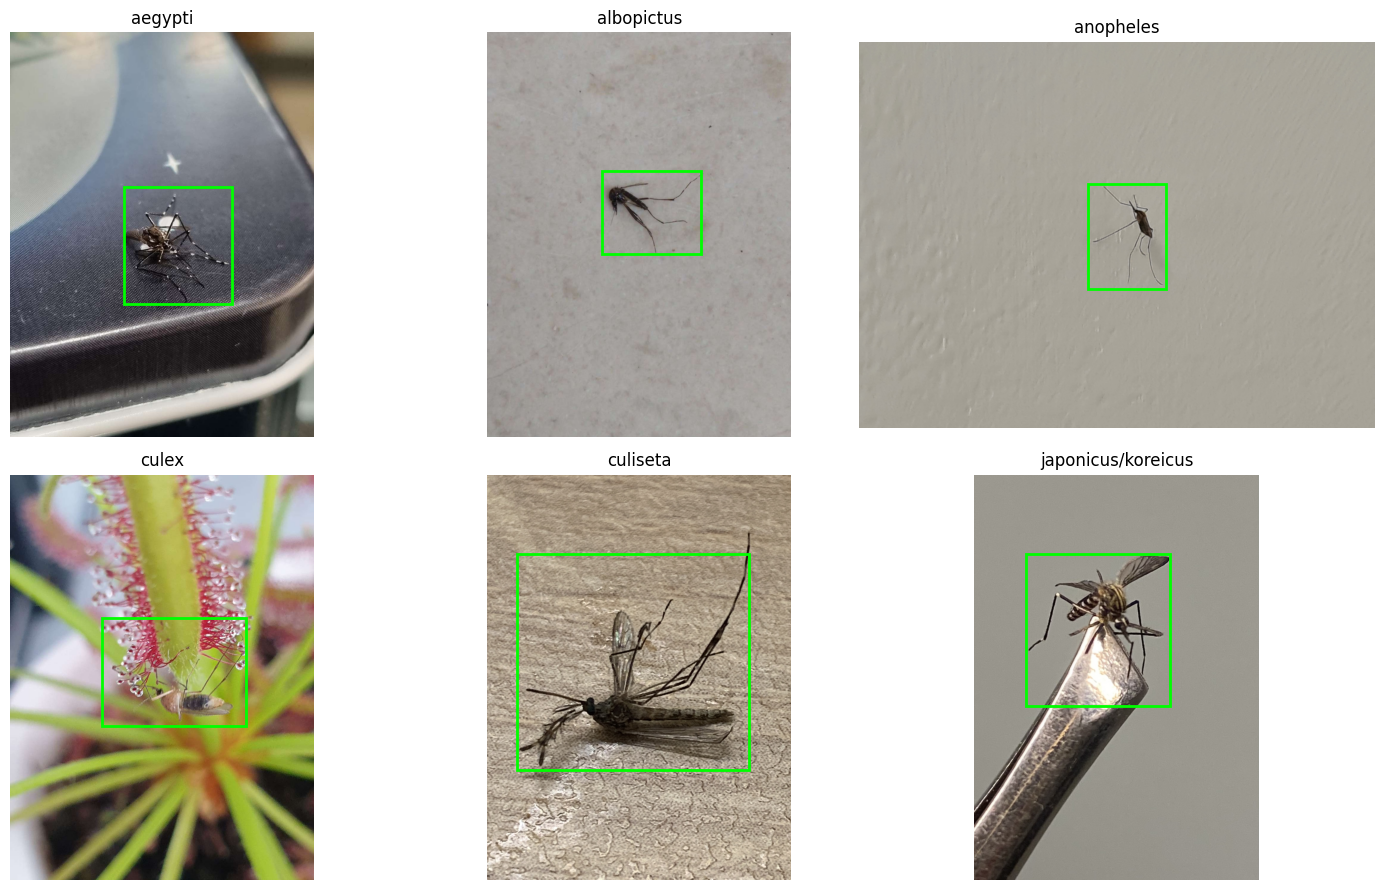

In [3]:
# A few training images with their boxes
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, cls_idx in zip(axes.ravel(), range(len(CLASS_NAMES))):
    name = next(f for f in train_images if labels[f] and int(labels[f][0][0]) == cls_idx)
    img = Image.open(os.path.join(train_img_dir, name)); w, h = img.size
    ax.imshow(img)
    for c, xc, yc, bw, bh in labels[name]:
        ax.add_patch(plt.Rectangle(((xc - bw / 2) * w, (yc - bh / 2) * h), bw * w, bh * h, fill=False, color="lime", lw=2))
    ax.set_title(CLASS_NAMES[cls_idx]); ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK, "sample_images.png"), dpi=90); plt.show()

## 3. Train/validation split
A **stratified** 90/10 split by each image's mosquito class keeps all six species in the same proportions in both sets. Images and labels are copied into the folder layout YOLO expects.

In [4]:
main_class = [int(labels[f][0][0]) if labels[f] else -1 for f in train_images]
tr_files, va_files = train_test_split(train_images, test_size=0.1, stratify=main_class, random_state=SEED)

for split, files in [("train", tr_files), ("val", va_files)]:
    os.makedirs(f"{WORK}/data/{split}/images", exist_ok=True)
    os.makedirs(f"{WORK}/data/{split}/labels", exist_ok=True)
    for f in files:
        shutil.copy(os.path.join(train_img_dir, f), f"{WORK}/data/{split}/images/{f}")
        lbl = os.path.join(train_lbl_dir, os.path.splitext(f)[0] + ".txt")
        if os.path.exists(lbl):
            shutil.copy(lbl, f"{WORK}/data/{split}/labels/")

with open(f"{WORK}/data.yaml", "w") as fh:
    fh.write(f"path: {WORK}/data\ntrain: train/images\nval: val/images\nnames:\n")
    for i, n in enumerate(CLASS_NAMES):
        fh.write(f"  {i}: {n}\n")
print(f"Train: {len(tr_files)}   Validation: {len(va_files)}")

Train: 6750   Validation: 750


## 4. Train YOLOv8
**YOLOv8m** (medium) pretrained on COCO is fine-tuned on the mosquito images. Because the photos are often **dark**, brightness augmentation (`hsv_v`) is raised above the default so the model sees a wider range of lighting. Training stops early if validation mAP stops improving for 10 epochs.

In [5]:
model = YOLO("yolov8m.pt")
results = model.train(
    data=f"{WORK}/data.yaml",
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=0,
    seed=SEED,
    patience=10,
    hsv_v=0.6,        # stronger brightness variation for low-light photos (default 0.4)
    degrees=10,       # small rotations
    flipud=0.2,       # occasional vertical flips
    project=f"{WORK}/runs",
    name="mosquito",
    exist_ok=True,
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.2, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.6, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mosquito, nbs=64, nms=None, opset=None, optimize=False, optimize

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


train: Scanning /kaggle/working/data/train/labels... 6750 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6750/6750 1.2Kit/s 5.5s
train: New cache created: /kaggle/working/data/train/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2825.8±1230.0 MB/s, size: 1497.1 KB)
val: Scanning /kaggle/working/data/val/labels... 750 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 1.2Kit/s 0.6s
val: New cache created: /kaggle/working/data/val/labels.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.001, momentum=0.9) with parameter groups 77 weight(decay=0.0), 84 weight(decay=0.0005), 83 bias(decay=0.0)
Plotting labels to /kaggle/working/runs/mosquito/labels.jpg... 
U

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      6.03G      1.473       1.59      1.632         26        640: 100% ━━━━━━━━━━━━ 422/422 2.2it/s 3:11
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.9it/s 12.4s
                   all        750        750      0.881      0.224      0.254      0.159

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      6.04G      1.437      1.517      1.601         28        640: 100% ━━━━━━━━━━━━ 422/422 2.2it/s 3:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.9it/s 12.3s
                   all        750        750      0.911      0.268      0.295      0.184

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      6.04G      1.392      1.456      1.576         27        640: 100% ━━━━━━━━━━━━ 422/422 2.2it/s 3:15
                 Class     Images  Instances      Box(

## 5. Validation results

In [6]:
best = YOLO(f"{WORK}/runs/mosquito/weights/best.pt")
metrics = best.val(data=f"{WORK}/data.yaml", imgsz=IMG_SIZE, device=0)
print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
per_class = pd.DataFrame({"class": CLASS_NAMES, "mAP@0.5:0.95": metrics.box.maps[:len(CLASS_NAMES)]})
print(per_class.round(4).to_string(index=False))

# Keep YOLO's own training plots for the README
for f in ["results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    p = f"{WORK}/runs/mosquito/{f}"
    if os.path.exists(p):
        shutil.copy(p, f"{WORK}/{f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,843,234 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4089.4±1103.1 MB/s, size: 1150.0 KB)
val: Scanning /kaggle/working/data/val/labels.cache... 750 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 262.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 2.4it/s 19.3s
                   all        750        750      0.755      0.448      0.543      0.405
               aegypti          4          4          1          0      0.421      0.309
            albopictus        333        333      0.842      0.898       0.91      0.687
             anopheles          6          6          1          0      0.142     0.0552
                 culex        331        331      0.868      0.949      0.952      0.719
              culiseta         46      

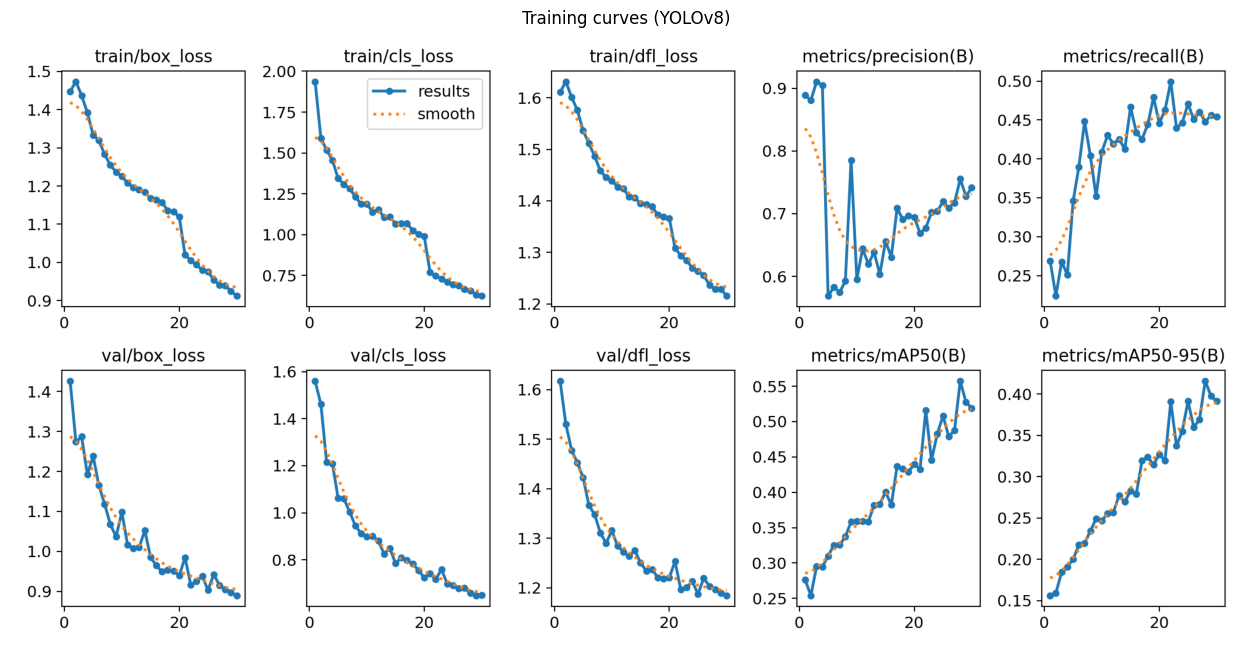

In [7]:
img = plt.imread(f"{WORK}/runs/mosquito/results.png")
plt.figure(figsize=(16, 8)); plt.imshow(img); plt.axis("off"); plt.title("Training curves (YOLOv8)"); plt.show()

## 6. Test predictions
Predictions use a low confidence threshold so that almost every image gets at least one box. The submission is written in the **exact format of `sample_submission.csv`**: the code checks whether it expects one row per image, class names or numbers, and normalised or pixel coordinates.

In [8]:
sample = pd.read_csv(sample_path)
print(sample.head()); print(sample.dtypes)

one_per_image = sample["ImageID"].is_unique
label_is_name = not pd.api.types.is_numeric_dtype(sample["LabelName"])
normalised = sample[["xcenter", "ycenter", "bbx_width", "bbx_height"]].max().max() <= 1.0
print(f"One row per image: {one_per_image} | class as name: {label_is_name} | normalised coords: {normalised}")

   id                                    ImageID   LabelName  Conf  xcenter  \
0   0  16dbbc39-fcb6-498e-963f-d3807fcc3cec.jpeg  albopictus   0.5      0.1   
1   1  7daa68bd-928b-4b43-850f-4626f16d2c14.jpeg  albopictus   0.5      0.1   
2   2  bb0986d9-fa04-40a5-8de2-c54045537e17.jpeg  albopictus   0.5      0.1   
3   3  11924d04-69fe-469d-8d1c-119bc0f0b94f.jpeg  albopictus   0.5      0.1   
4   4  db4ade79-fce4-4d77-a8fa-36b9e77dfd08.jpeg  albopictus   0.5      0.1   

   ycenter  bbx_width  bbx_height  
0      0.2        0.3         0.4  
1      0.2        0.3         0.4  
2      0.2        0.3         0.4  
3      0.2        0.3         0.4  
4      0.2        0.3         0.4  
id              int64
ImageID        object
LabelName      object
Conf          float64
xcenter       float64
ycenter       float64
bbx_width     float64
bbx_height    float64
dtype: object
One row per image: True | class as name: True | normalised coords: True


In [9]:
test_by_stem = {os.path.splitext(f)[0]: f for f in test_images}
preds = {}
for r in best.predict(source=test_img_dir, imgsz=IMG_SIZE, conf=0.01, iou=0.5, device=0, stream=True, verbose=False):
    name = os.path.basename(r.path)
    b = r.boxes
    preds[name] = [(int(c), float(s), *map(float, xywhn)) for c, s, xywhn in zip(b.cls, b.conf, b.xywhn)]
    preds[name].sort(key=lambda t: -t[1])

rows = []
for image_id in sample["ImageID"].drop_duplicates():
    fname = image_id if image_id in preds else test_by_stem.get(os.path.splitext(image_id)[0], image_id)
    dets = preds.get(fname, [])
    if not dets:  # no detection: fall back to a centred box of the most common class
        dets = [(max(class_counts, key=class_counts.get), 0.01, 0.5, 0.5, 0.5, 0.5)]
    if one_per_image:
        dets = dets[:1]
    w, h = Image.open(os.path.join(test_img_dir, fname)).size
    for c, s, xc, yc, bw, bh in dets:
        if not normalised:
            xc, yc, bw, bh = xc * w, yc * h, bw * w, bh * h
        rows.append({"ImageID": image_id, "LabelName": CLASS_NAMES[c] if label_is_name else c,
                     "Conf": s, "xcenter": xc, "ycenter": yc, "bbx_width": bw, "bbx_height": bh})

submission = pd.DataFrame(rows)
submission.insert(0, "id", range(len(submission)))
submission = submission[sample.columns]
submission.to_csv(f"{WORK}/submission.csv", index=False)
print(submission.shape); print(submission.head())
print(submission["LabelName"].value_counts())

(525, 8)
   id                                    ImageID   LabelName      Conf  \
0   0  16dbbc39-fcb6-498e-963f-d3807fcc3cec.jpeg  albopictus  0.788697   
1   1  7daa68bd-928b-4b43-850f-4626f16d2c14.jpeg  albopictus  0.866462   
2   2  bb0986d9-fa04-40a5-8de2-c54045537e17.jpeg  albopictus  0.713260   
3   3  11924d04-69fe-469d-8d1c-119bc0f0b94f.jpeg       culex  0.696089   
4   4  db4ade79-fce4-4d77-a8fa-36b9e77dfd08.jpeg       culex  0.459755   

    xcenter   ycenter  bbx_width  bbx_height  
0  0.433077  0.452270   0.144833    0.115689  
1  0.497464  0.564572   0.469661    0.330171  
2  0.356230  0.468132   0.108112    0.176961  
3  0.614844  0.615463   0.770313    0.752042  
4  0.367141  0.471475   0.192714    0.133841  
LabelName
culex                 244
albopictus            243
culiseta               35
japonicus/koreicus      3
Name: count, dtype: int64


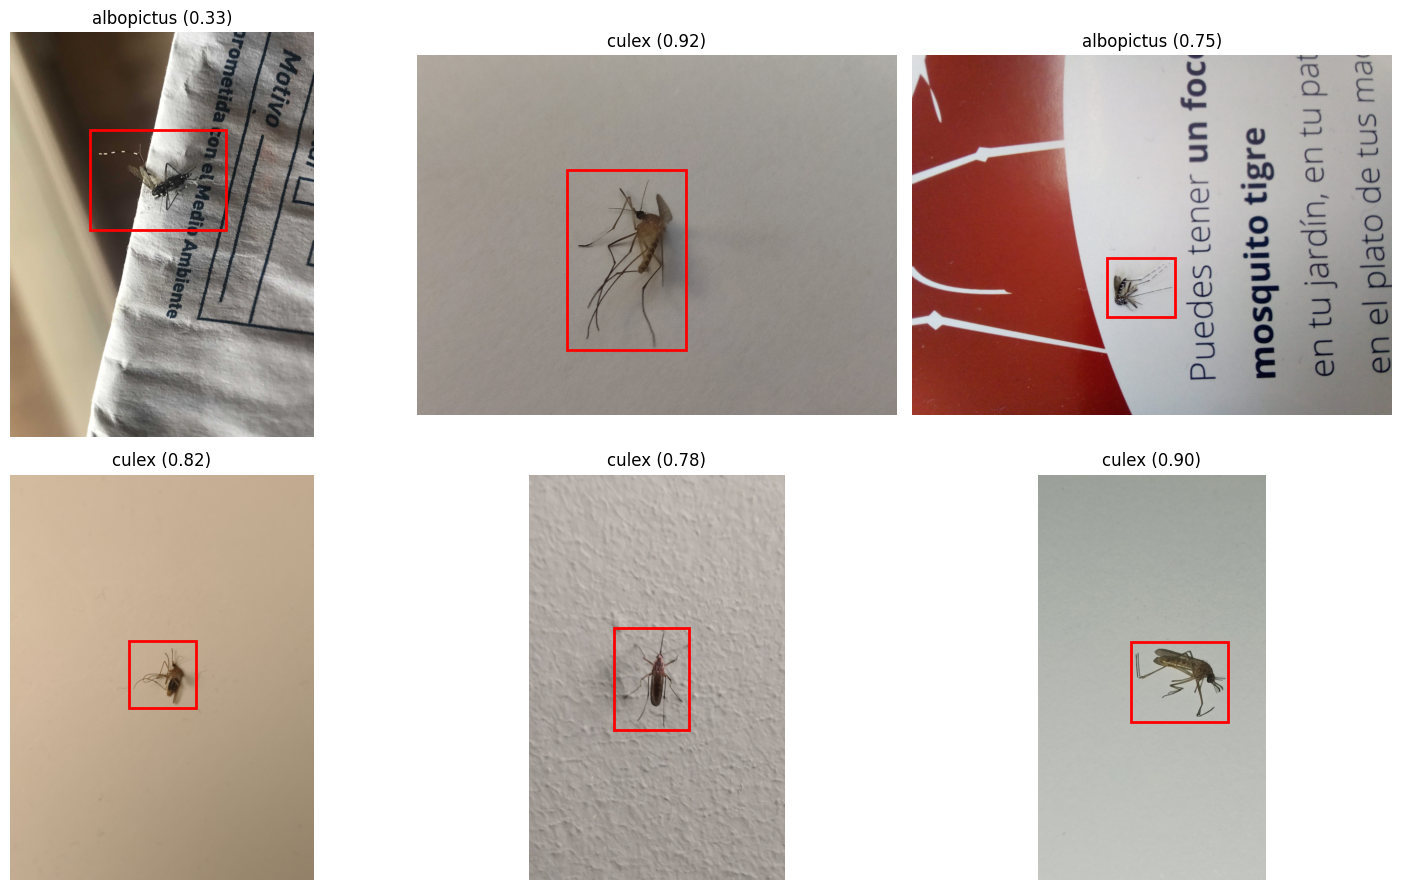

In [10]:
# Predicted boxes on a few test images
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, fname in zip(axes.ravel(), random.sample(list(preds), 6)):
    img = Image.open(os.path.join(test_img_dir, fname)); w, h = img.size
    ax.imshow(img)
    if preds[fname]:
        c, s, xc, yc, bw, bh = preds[fname][0]
        ax.add_patch(plt.Rectangle(((xc - bw / 2) * w, (yc - bh / 2) * h), bw * w, bh * h, fill=False, color="red", lw=2))
        ax.set_title(f"{CLASS_NAMES[c]} ({s:.2f})")
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/test_predictions.png", dpi=90); plt.show()

## 7. Summary
Validation mAP and per-class results are printed above. Ideas to improve: a larger input size (e.g. 1024) for small mosquitoes, a larger model (YOLOv8l), longer training, or low-light enhancement (e.g. CLAHE) applied to both training and test images.